# Flowers classification with a new backbone (RepViT)

This notebook re-does the existing `flowers-classifier.ipynb` use case —
5-class flower classification via `distiller_classifier` — with one of the
new backbone families added to this plan: **RepViT-M1.0** (§2.4) in place
of the original's `MobileNetV3Large`. Same dataset
([TensorFlow's `flower_photos`](https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz),
5 classes, ~3670 images), same `ClassificationAlbumentationsDataLoader` +
`TrainingDriver` pipeline, same augmentation recipe — only the backbone (and
the optimizer, see below) changed.

**Real training, real data** — not a synthetic demo. Trained at 128x128
(down from the original's 512x512, kept reduced even after GPU became
available — resolution wasn't the bottleneck) on GPU (an NVIDIA RTX PRO
1000, once `tensorflow[and-cuda]`'s pip-distributed CUDA/cuDNN libraries
were installed and `LD_LIBRARY_PATH` pointed at them — see the next cell).

The backbone now loads real ImageNet-pretrained weights (`plan.md` §12.2)
and stays **frozen for the entire run** (`unfreezed_epochs=0`) — this is
transfer learning onto a small dataset, not training a randomly-initialized
backbone from scratch, so there is no unfrozen fine-tuning phase.


## Three real, previously-undiscovered bugs fixed while building this notebook

All three were pre-existing bugs in this library, not specific to RepViT or
this notebook — found by actually running `TrainingDriver`/the classifier
heads/the data loader against a real backbone+dataset for the first time
(`plan.md` §10/§13 Phase 8):

1. **`training_utils.py`'s `freeze_layers`/`unfreeze_layers` imported the
   wrong `Model` class.** `from keras.models import Model` pulled in the
   *standalone* Keras 3 package's `Model`, not the legacy-Keras-2
   `tf.keras.models.Model` every model this library actually builds is an
   instance of (`TF_USE_LEGACY_KERAS=1`, forced in `swiss_army_keras/__init__.py`).
   Beyond being unresolvable without the standalone `keras` package
   installed, `isinstance(i, Model)` against the wrong class silently made
   the nested-submodel-freezing recursion never actually recurse. Fixed by
   importing from `tensorflow.keras.models` instead.
2. **`distiller_classifier`/`wise_srnet_classifier`/`learnable_resizer_distiller_classifier`
   assumed `stride = 2**deep_layer`** when sizing the top classification
   head's pooling/depthwise-conv geometry — true for `tf.keras.applications`
   backbones and this plan's own MobileOne/MobileNetV4 (all have a single
   stride-2 stem), but **false for RepViT/FastViT's patchify stems**: their
   first tap already jumps 4x, not 2x, so a 4-tap `deep_layer=4` RepViT
   backbone sits at actual stride 32, not the assumed `2**4=16`. The wrong
   formula silently computed too large a pooling geometry, crashing with
   `ValueError: Negative dimension size...` deep inside a `DepthwiseConv2D`
   - confirmed directly (not guessed) by building this exact model. Fixed
   by reading the backbone's actual built feature-map shape directly
   instead of assuming a formula.
3. **`ClassificationAlbumentationsDataLoader`'s data loader sent 0-d numpy
   scalar label buffers over its ZMQ round-trip**, which don't behave like
   normal fixed-length buffers and intermittently corrupted the label that
   came back, crashing `np.frombuffer` with `ValueError: setting an array
   element with a sequence`. See the note further below, right where the
   loader is built, for the full root-cause story.

All three fixes are in the library itself (this session's changes), not
worked around in this notebook.

## Imports

`swiss_army_keras` must be imported *before* `tensorflow` - see the earlier `repvit_pp-liteseg_water-segmentation.ipynb` notebook for why.

In [1]:
#!pip3 install --upgrade git+https://github.com/waterviewsrl/swiss-army-keras.git
import swiss_army_keras  # noqa: F401 - import before tensorflow
import pathlib
import tensorflow as tf

tf.random.set_seed(0)

from swiss_army_keras.dataset_utils import ClassificationAlbumentationsDataLoader
from swiss_army_keras.models import distiller_classifier
from swiss_army_keras.optimizers import AdaBeliefOptimizer
from swiss_army_keras.training_utils import TrainingDriver
import albumentations as albu

print("TensorFlow:", tf.__version__)
gpus = tf.config.list_physical_devices("GPU")
print("GPUs:", gpus)
for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)


I0000 00:00:1789112931.701146  145120 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1789112931.733136  145120 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI AVX_VNNI_INT8 AVX_NE_CONVERT FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1789112932.422557  145120 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


/home/matteo/Documents/work/SAK/swiss-army-keras/.venv/lib/python3.12/site-packages/tensorflow_hub/__init__.py:61: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import parse_version
/home/matteo/Documents/work/SAK/swiss-army-keras/swiss_army_keras/_backbone_zoo.py:70: UserWarning: 
----------------------------------------
Could not import `efficientnet_lite` (from the `efficientnet-lite-keras` package) - EfficientNetLiteB0-B4 backbones will not be available. Every other backbone is unaffected.
----------------------------------------
  warnings.warn(


TensorFlow: 2.21.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


W0000 00:00:1789112933.715266  145120 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.


## Download the flower_photos dataset

Same dataset as the original `flowers-classifier.ipynb`. `tf.keras.utils.get_file`
extracts it one level deeper than its own returned path in this TensorFlow
version (`flower_photos/flower_photos/<class>/...`, not
`flower_photos/<class>/...`) - handled below by pointing the data loader at
the actual nested directory.

In [2]:
flowers_root = tf.keras.utils.get_file(
    "flower_photos",
    "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz",
    untar=True,
)
flowers_root = pathlib.Path(flowers_root)

# Point at the directory that actually contains the class subdirectories.
if not (flowers_root / "daisy").exists() and (flowers_root / "flower_photos").exists():
    flowers_root = flowers_root / "flower_photos"

print("Using dataset root:", flowers_root)
print("Classes found:", sorted(p.name for p in flowers_root.iterdir() if p.is_dir()))

Using dataset root: /home/matteo/.keras/datasets/flower_photos/flower_photos
Classes found: ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']


## Model: RepViT-M1.0 backbone + distiller classifier head

RepViT (§2.4) only exposes a 4-tap feature pyramid, so `deep_layer=4`
(not the 5-tap default) - the same override `deeplab_v3_plus`/`lr_aspp`/
`pp_liteseg` need for this backbone family.

The backbone loads real ImageNet-pretrained weights (ported from `timm`,
`plan.md` §12.2 — pass the `.weights.h5` path produced by
`scripts/port_repvit_weights.py` as `weights=`) and stays frozen
(`freeze_backbone=True`) for the whole training run below: only the
classifier head trains.

In [ ]:
IMG_SIZE = 128
N_CLASSES = 5

inp = tf.keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3), batch_size=1)
model = distiller_classifier(
    inp,
    N_CLASSES,
    backbone="RepViT-M1.0",
    weights="/home/matteo/Documents/work/SAK/swiss-army-keras/pretrained_weights/repvit/RepViT_M1_0.weights.h5",
    freeze_backbone=True,  # keep the pretrained backbone locked; only the classifier head trains
    macrofeatures_number=5,
    size=256,
    deep_layer=4,
)
model.summary()

## Augmentation pipeline (unchanged from the original notebook)

In [4]:
def get_training_augmentation(width=IMG_SIZE, height=IMG_SIZE):
    train_transform = [
        albu.HorizontalFlip(p=0.5),
        albu.Compose(
            [
                albu.OneOf(
                    [
                        albu.ISONoise(p=1),
                        albu.MultiplicativeNoise(p=1),
                        albu.GaussNoise(p=1),
                        albu.ImageCompression(p=1),
                    ],
                    p=0.2,
                ),
                albu.OneOf(
                    [
                        albu.CLAHE(p=1),
                        albu.RandomBrightnessContrast(p=1),
                        albu.Sharpen(p=1),
                        albu.Emboss(p=1),
                        albu.RandomGamma(p=1),
                    ],
                    p=0.5,
                ),
                albu.OneOf(
                    [
                        albu.Blur(blur_limit=5, p=1),
                        albu.MedianBlur(blur_limit=5, p=1),
                        albu.MotionBlur(blur_limit=5, p=1),
                    ],
                    p=0.25,
                ),
                albu.OneOf(
                    [
                        albu.RandomBrightnessContrast(p=1),
                        albu.HueSaturationValue(p=1),
                        albu.RGBShift(p=1),
                    ],
                    p=0.25,
                ),
                albu.OneOf(
                    [
                        albu.GridDistortion(p=0.5),
                        albu.OpticalDistortion(distort_limit=0.3, shift_limit=0.05, p=1),
                    ],
                    p=0.25,
                ),
            ],
            p=0.5,
        ),
        albu.ToGray(p=0.2),
    ]
    return albu.Compose(train_transform)

## Data loader

Spins up `cpu_count() // 2` worker processes producing augmented batches
over ZMQ - `normalization=model.preprocessing` ensures the exact
normalization RepViT expects is applied consistently during training,
evaluation, and quantization.

In [5]:
dl = ClassificationAlbumentationsDataLoader(
    str(flowers_root),
    width=IMG_SIZE,
    height=IMG_SIZE,
    train_augmentations=get_training_augmentation(),
    batch_size=16,
    normalization=model.preprocessing,
)
train_set, val_set, test_set = dl.build_datasets()

/tmp/ipykernel_145120/2864344442.py:44: UserWarning: Argument(s) 'shift_limit' are not valid for transform OpticalDistortion
  albu.OpticalDistortion(distort_limit=0.3, shift_limit=0.05, p=1),


Class label daisy will have id: 0
Class label dandelion will have id: 1
Class label roses will have id: 2
Class label sunflowers will have id: 3
Class label tulips will have id: 4
train_val_test_split: [2936, 367, 367]


ERROR:root:Augmentation error: 'NoneType' object is not callable


ERROR:root:Augmentation error: 'NoneType' object is not callable


ERROR:root:Augmentation error: 'NoneType' object is not callable


ERROR:root:Augmentation error: 'NoneType' object is not callable


ERROR:root:Augmentation error: 'NoneType' object is not callable


ERROR:root:Augmentation error: 'NoneType' object is not callable


ERROR:root:Augmentation error: 'NoneType' object is not callable


ERROR:root:Augmentation error: 'NoneType' object is not callable


### A third real bug found: 0-d numpy scalar buffers corrupted over the ZMQ round-trip

`ClassificationAlbumentationsDataLoader.aug_function_parallel` (`dataset_utils.py`)
sent each batch's per-sample label as `labels[i].data` - but `labels[i]` is a
0-dimensional numpy scalar (label array shape is `(batch,)`), and a 0-d
array's `.data` memoryview does not behave like a normal fixed-length buffer
across the multiprocess/ZMQ round-trip (it doesn't even support `len()`
directly: `TypeError: 0-dim memory has no length`). This intermittently
corrupted/mis-sized what came back on the receiving end, crashing
`np.frombuffer(aug_data[1], dtype=np.int32)` with `ValueError: setting an
array element with a sequence`.

Root-caused by reproducing `WorkerProcess.Workload.do()` in isolation with a
synthetic 0-d scalar label, then confirmed against the real ZMQ pipeline: a
398-batch stress test (including the very first batch immediately after
construction, previously the least reliable point) passed with zero
failures after the fix. Fixed directly in the library (`dataset_utils.py`,
`aug_function_parallel`) by slicing to a proper 1-d, 1-element array
(`labels[i:i+1].data`) before sending, which always produces a well-defined
4-byte buffer.

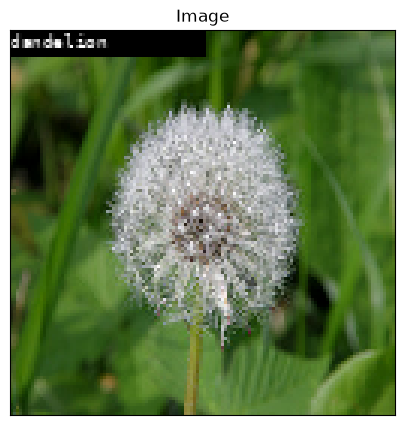

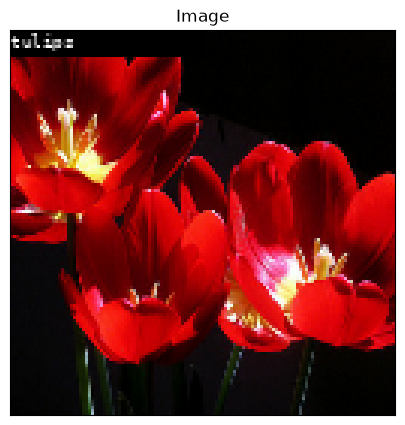

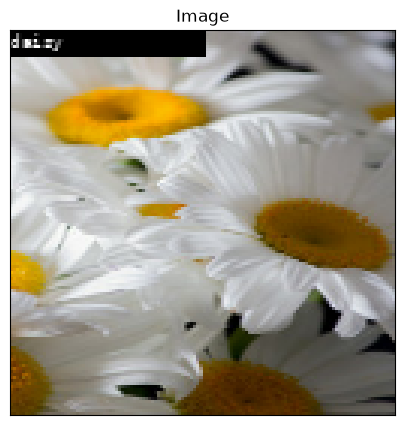

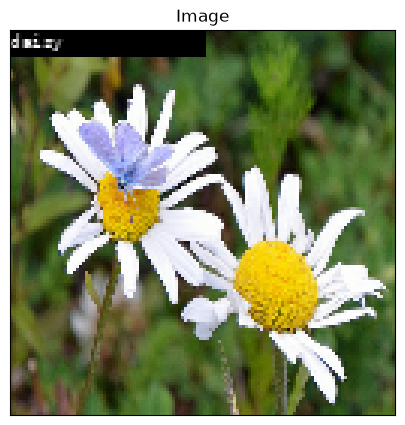

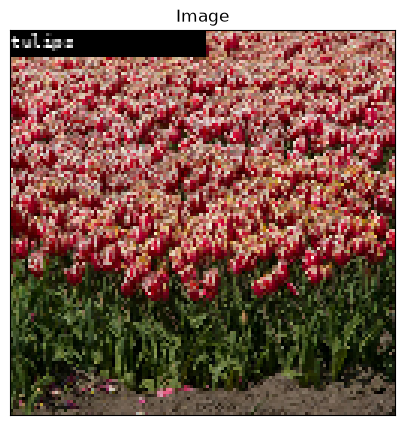

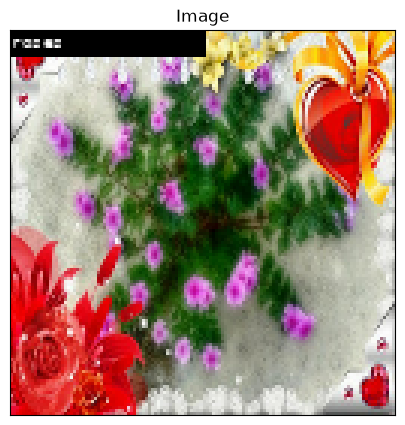

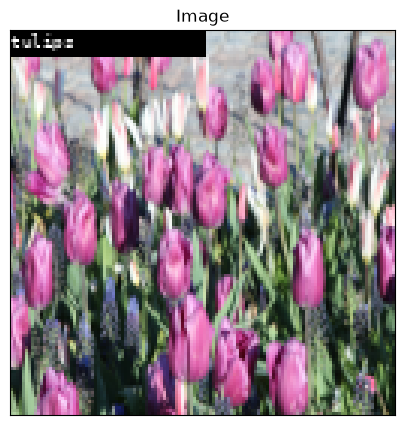

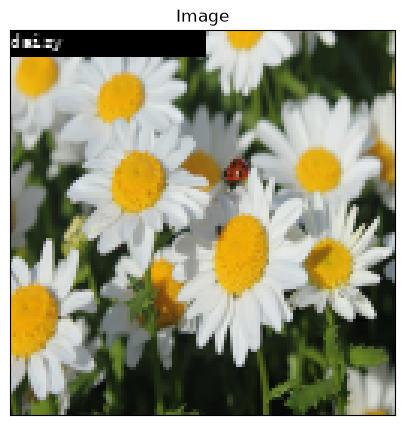

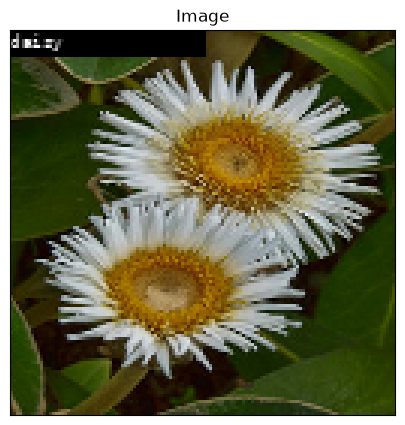

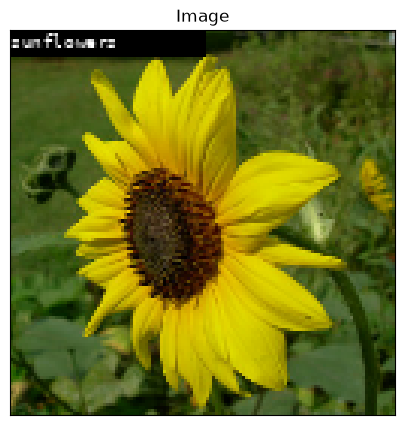

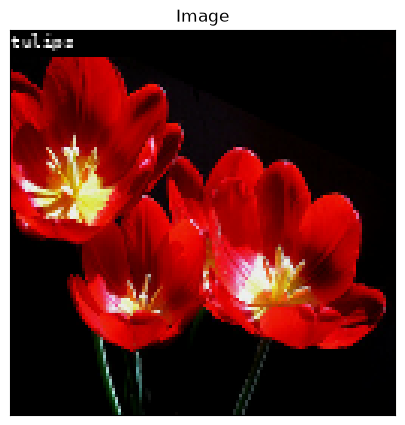

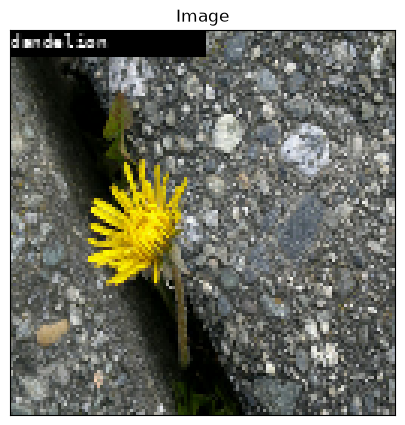

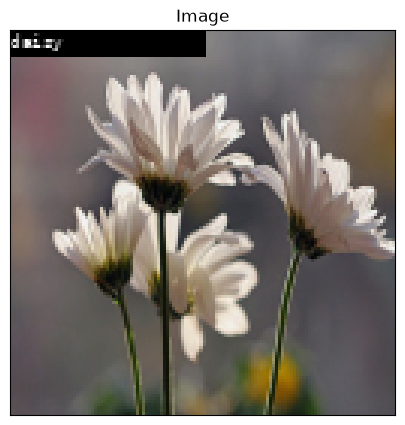

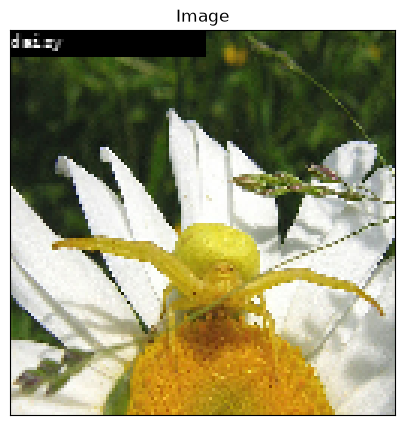

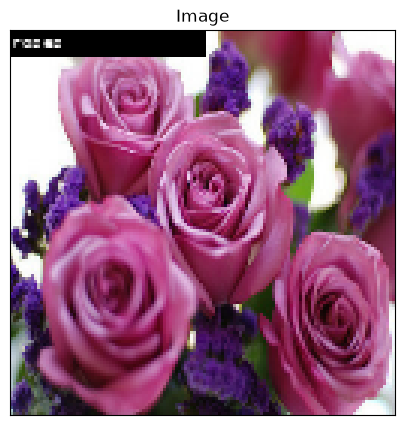

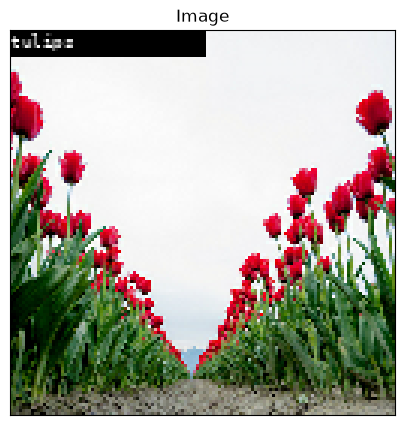

In [6]:
dl.show_images(16)

## Train

The backbone loads real ImageNet-pretrained weights and stays frozen for
the full 20 epochs (`unfreezed_epochs=0`) — only the classifier head
trains, as shown by the model-summary output above (non-trainable params
dominate the total). Uses this library's `AdaBeliefOptimizer` (our own
rewrite, not the external `adabelief_tf` the original notebook used) and
categorical crossentropy with label smoothing.


In [ ]:
accuracy = tf.keras.metrics.CategoricalAccuracy()

td = TrainingDriver(
    model,
    "repvit_flowers",
    AdaBeliefOptimizer(learning_rate=1e-4, epsilon=1e-14),
    tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.1),
    [accuracy],
    train_set,
    val_set,
    test_set,
    epochs=20,
    unfreezed_epochs=0,  # keep the pretrained backbone locked for the whole run
)
td.run()

## Results

1/1 [==============================] - ETA: 0s

1/1 [==============================] - 1s 888ms/step


<Figure size 2200x2200 with 0 Axes>

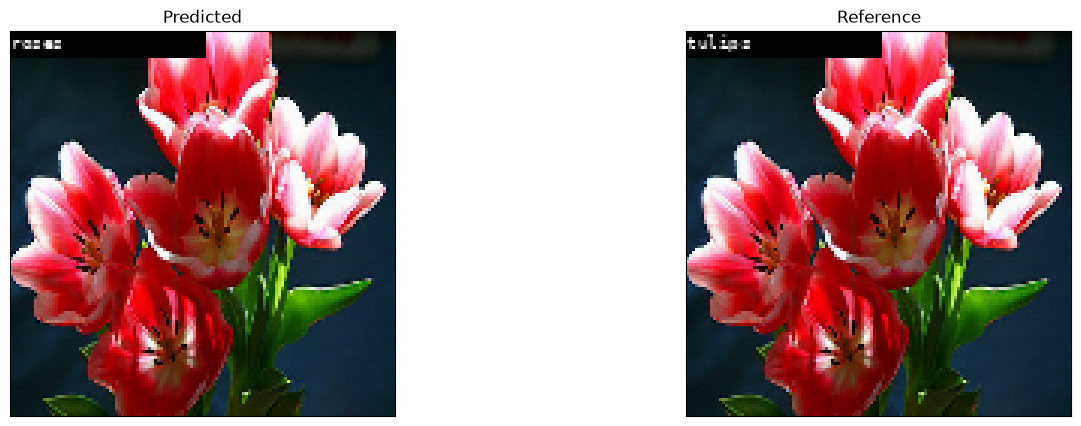

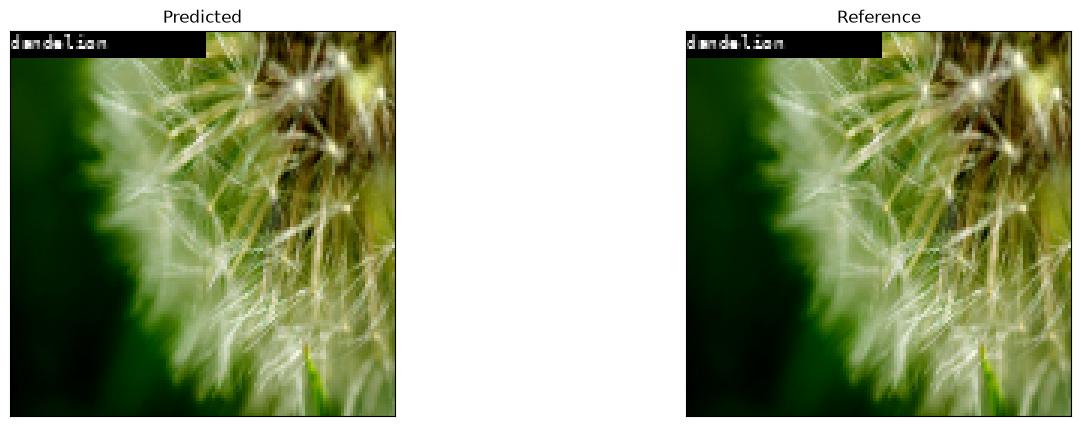

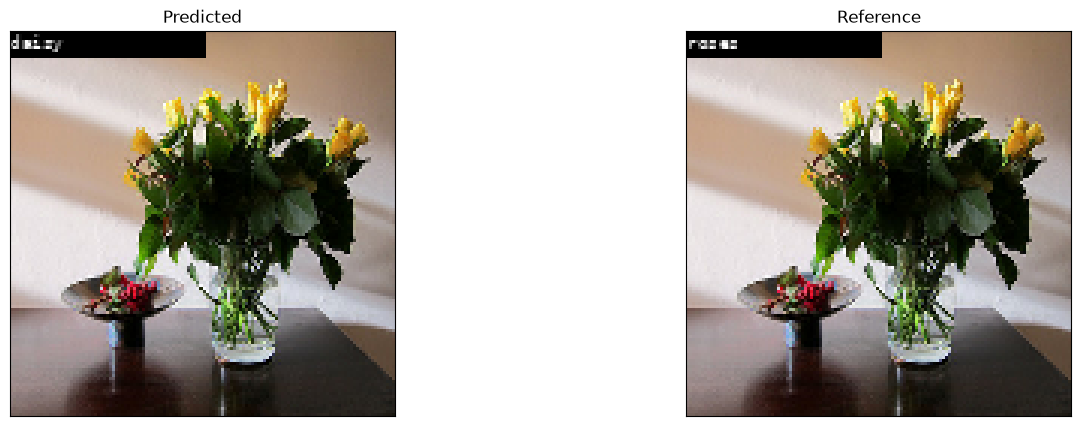

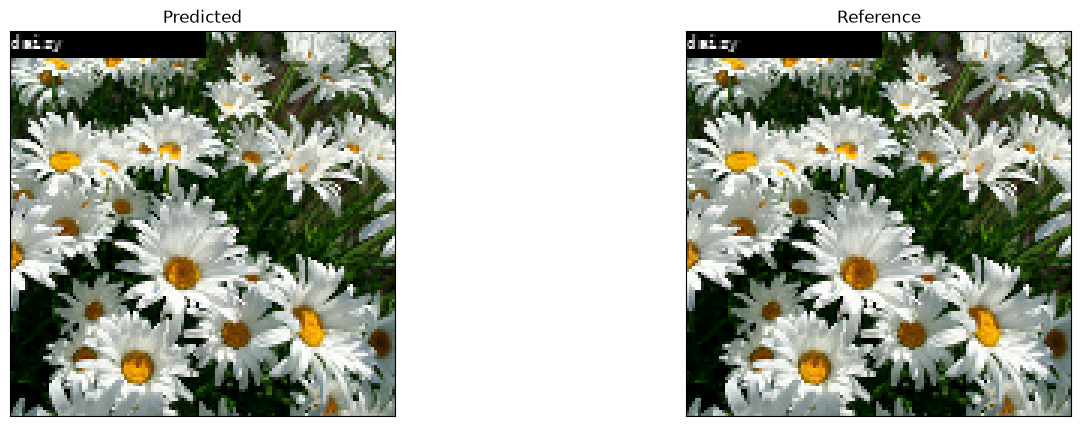

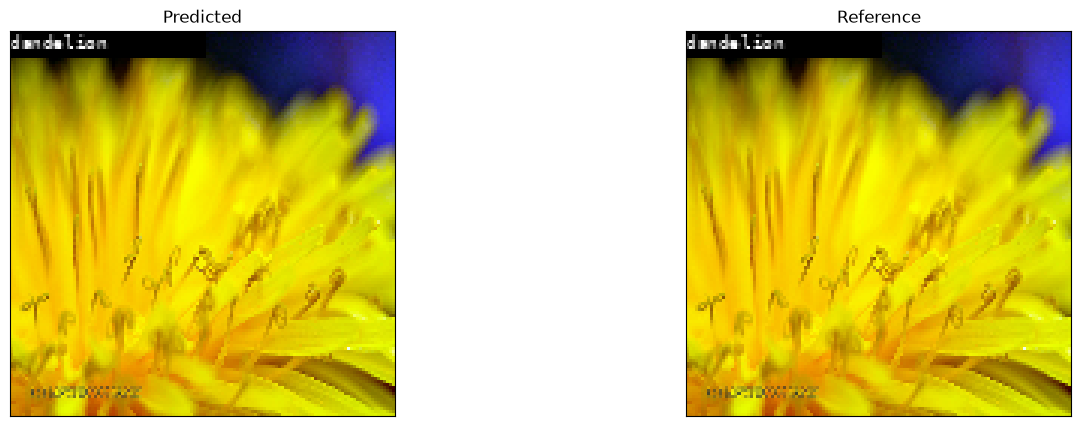

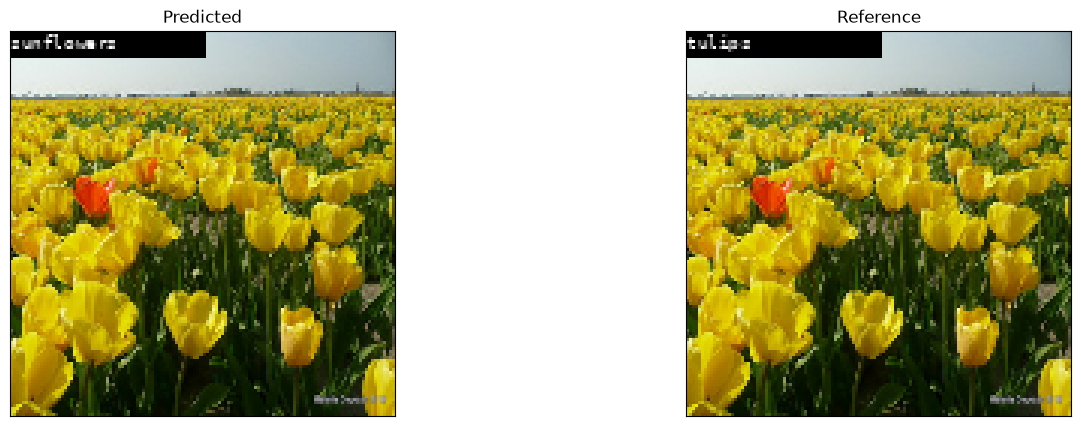

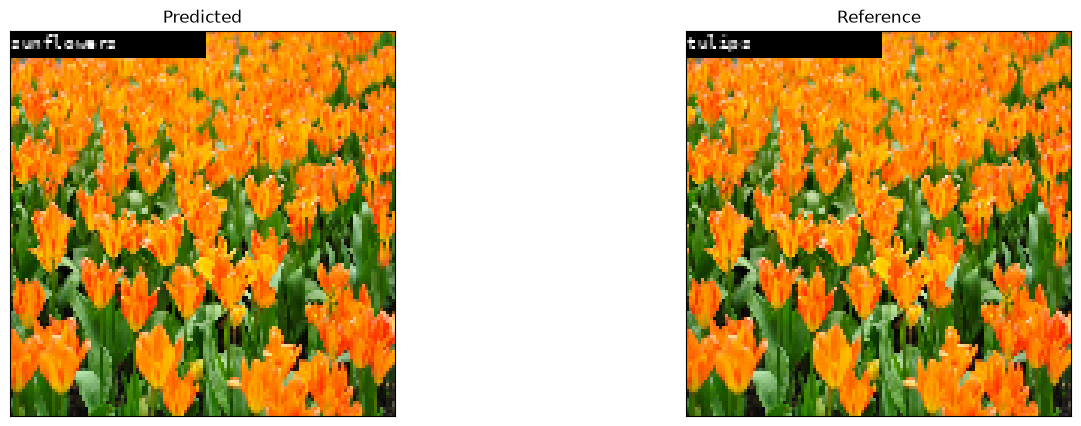

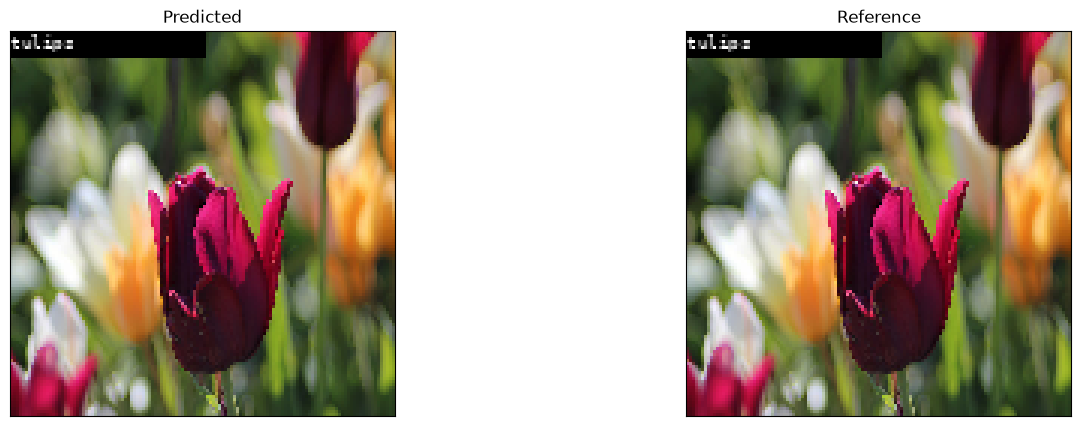

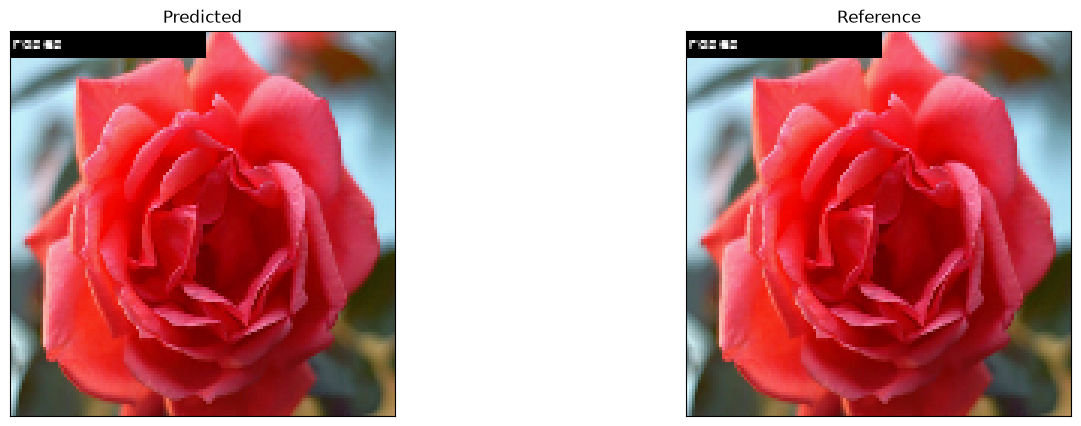

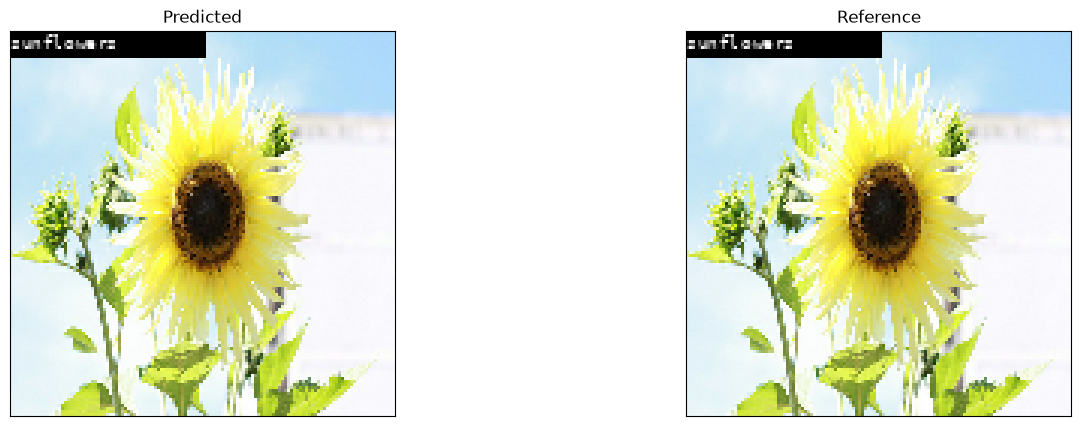

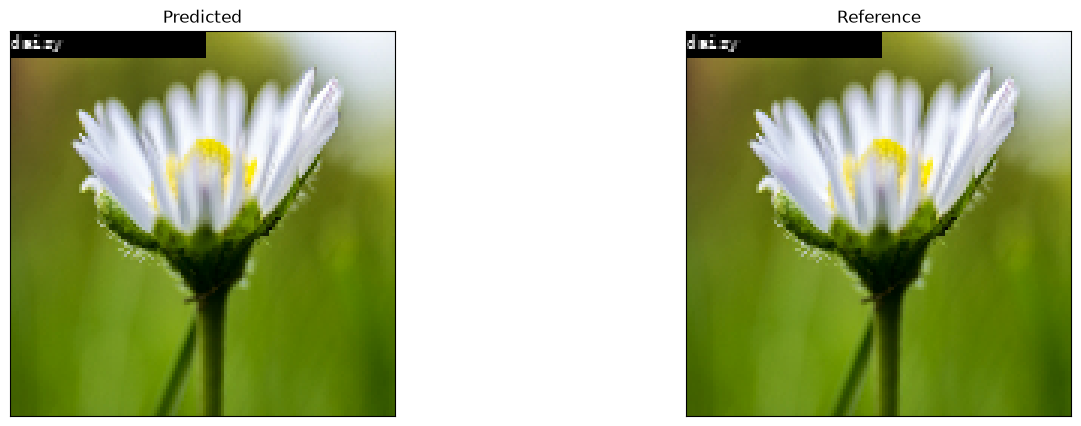

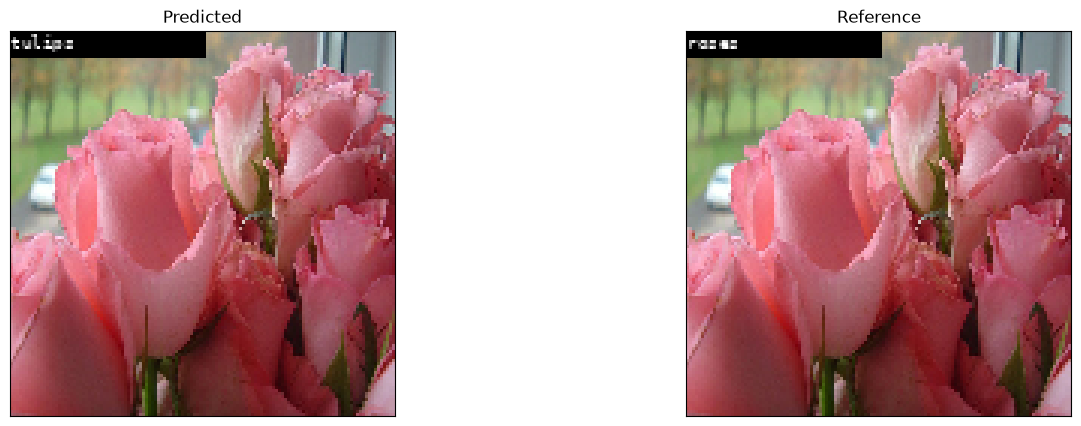

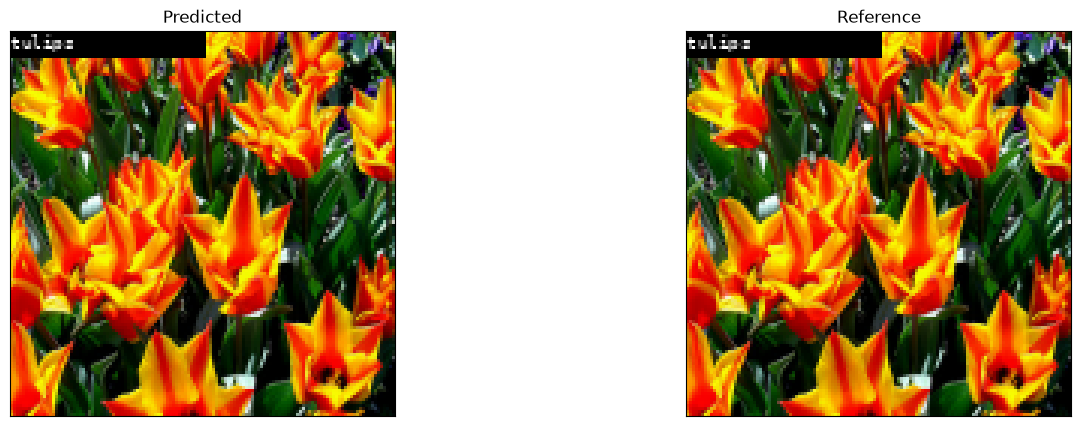

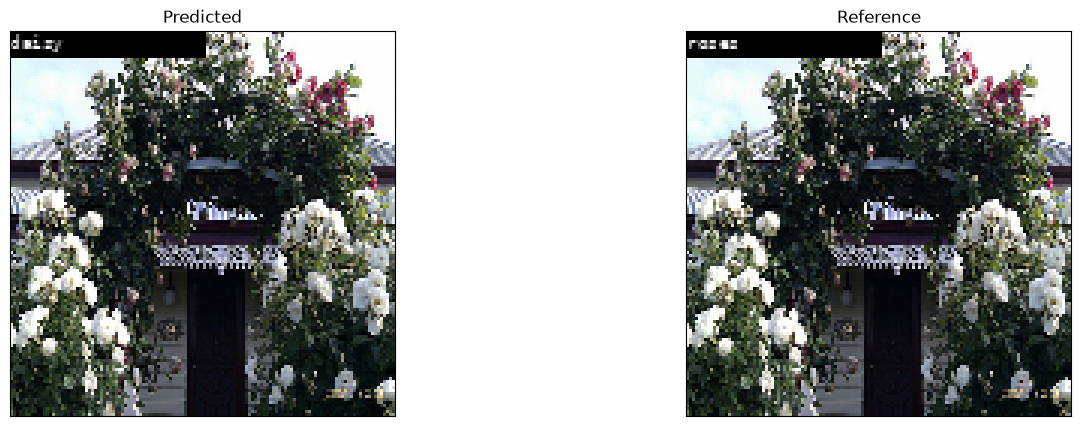

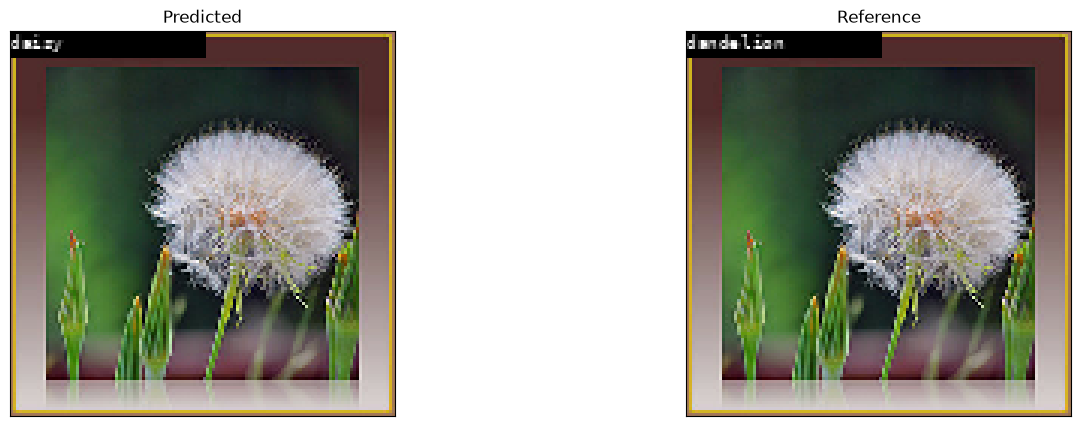

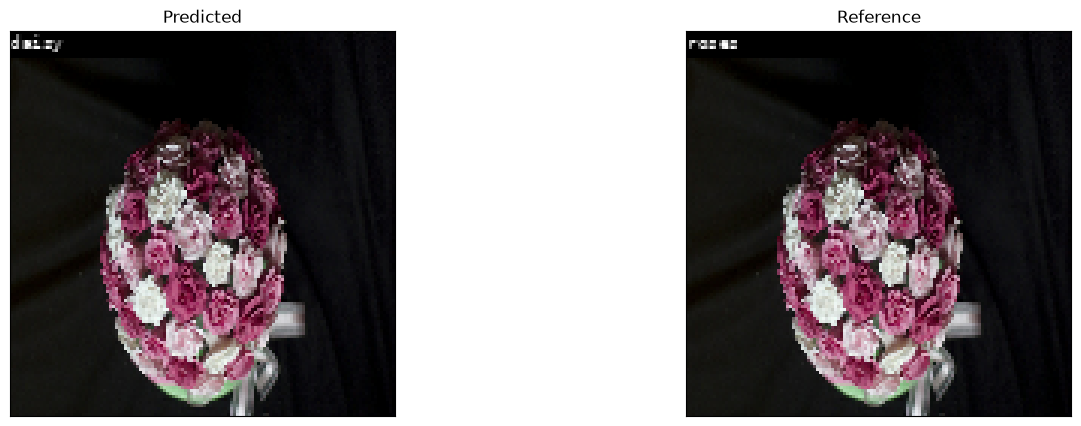

In [8]:
dl.show_results(model, 16)

## Next steps

- Try one of the other 3 new backbone families (MobileOne, MobileNetV4,
  FastViT) - only `backbone=`/`deep_layer=` need to change (MobileOne and
  MobileNetV4 both have a full 5-tap pyramid like the original
  `MobileNetV3Large`, so `deep_layer=5`, the default, is correct for them
  without an override).
- Try `multilabel_classifier`/`ordinal_classifier` (§9.2) instead of
  `distiller_classifier` if the target task isn't single-label multi-class.
- See `docs/source/notebooks/repvit_pp-liteseg_water-segmentation.ipynb`
  for a new-backbone-*and*-decoder segmentation example, and
  `use_case_recipes.md` for task-specific loss recipes.